# Практическая работа № 9. Метод опорных векторов

**Цель:** исследовать влияние ядра RBF и гиперпараметров `C` и `gamma`, корректно подобрать параметры кросс-валидацией и сравнить SVM с моделями ПР-7 и ПР-8.

Используется датасет Telco Customer Churn и то же stratified-разбиение 80/20 с `random_state=42`, что и в предыдущих работах. Масштабирование включено в pipeline, поэтому в каждом CV-fold оно обучается только на соответствующей тренировочной части.

In [1]:
from pathlib import Path
from time import perf_counter
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
DATA_CANDIDATES = [Path("data/raw/Churn.csv"), Path("../data/raw/Churn.csv"), Path("../../data/raw/Churn.csv")]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Не найден data/raw/Churn.csv. Запустите ноутбук из корня репозитория или notebooks/practice_9.")

df = pd.read_csv(DATA_PATH)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
y = df["Churn"].map({"Yes": 1, "No": 0})
X = pd.get_dummies(df.drop(columns=["customerID", "Churn"]), drop_first=True, dtype=int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Объектов: {len(df)}; признаков после one-hot: {X.shape[1]}")
print(f"Единое разбиение train/test: {len(X_train)}/{len(X_test)}")

Объектов: 7043; признаков после one-hot: 30
Единое разбиение train/test: 5634/1409


## 1. Сетка параметров для RBF SVM

Сравниваем 16 пар значений `C` и `gamma` на 3-fold stratified CV только внутри train. Для выбора используется `macro-F1`, чтобы учитывать оба класса при дисбалансе. Дополнительно сохраняется CV accuracy. Тестовая выборка остаётся нетронутой до итогового сравнения.

- Малое `C` сильнее допускает ошибки и регуляризует модель; большое `C` сильнее подстраивается под обучающие объекты.
- Малое `gamma` даёт более гладкое влияние объектов; большое `gamma` делает границу локальной и повышает риск переобучения.

In [2]:
pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("svc", SVC(kernel="rbf", cache_size=512, random_state=RANDOM_STATE)),
])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [0.001, 0.01, 0.1, 1],
}
search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
    refit="f1_macro",
    cv=cv,
    n_jobs=2,
    return_train_score=True,
)
grid_start = perf_counter()
search.fit(X_train, y_train)
grid_seconds = perf_counter() - grid_start

grid_results = pd.DataFrame(search.cv_results_)
grid_results = grid_results[[
    "param_svc__C", "param_svc__gamma", "mean_test_accuracy", "std_test_accuracy",
    "mean_test_f1_macro", "std_test_f1_macro", "mean_train_f1_macro", "mean_fit_time",
]].rename(columns={
    "param_svc__C": "C", "param_svc__gamma": "gamma",
    "mean_test_accuracy": "CV accuracy", "std_test_accuracy": "SD accuracy",
    "mean_test_f1_macro": "CV macro-F1", "std_test_f1_macro": "SD macro-F1",
    "mean_train_f1_macro": "Train CV macro-F1", "mean_fit_time": "Среднее время fit, с",
}).sort_values("CV macro-F1", ascending=False).reset_index(drop=True)
display(grid_results.round(4))
print("Лучшие параметры:", search.best_params_)
print(f"Лучшая средняя CV macro-F1: {search.best_score_:.4f}")
print(f"Время полного grid search вместе с CV и refit: {grid_seconds:.2f} с")

,C,gamma,CV accuracy,SD accuracy,CV macro-F1,SD macro-F1,Train CV macro-F1,"Среднее время fit, с"
0,10.0,0.001,0.8024,0.0076,0.7279,0.0085,0.7299,0.4512
1,100.0,0.001,0.8058,0.0074,0.7276,0.0075,0.7350,0.4967
2,10.0,0.010,0.8040,0.0037,0.7267,0.0057,0.7516,0.5599
3,1.0,0.010,0.8032,0.0067,0.7204,0.0068,0.7319,0.4188
4,1.0,0.001,0.8001,0.0083,0.7193,0.0089,0.7209,0.4435
5,100.0,0.010,0.7911,0.0051,0.7187,0.0097,0.8018,0.9685
6,1.0,0.100,0.7957,0.0055,0.7158,0.0082,0.8134,0.5372
7,0.1,0.010,0.7923,0.0050,0.6979,0.0036,0.7080,0.4728
8,10.0,0.100,0.7570,0.0024,0.6805,0.0023,0.9309,0.7059
9,100.0,0.100,0.7412,0.0054,0.6592,0.0061,0.9512,0.6974


Лучшие параметры: {'svc__C': 10, 'svc__gamma': 0.001}
Лучшая средняя CV macro-F1: 0.7279
Время полного grid search вместе с CV и refit: 52.63 с


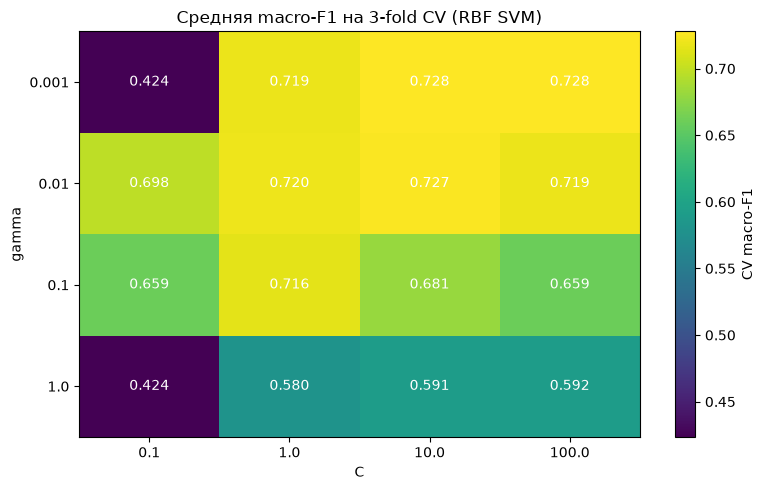

param_svc__C,0.1,1.0,10.0,100.0
param_svc__gamma,,,,
0.001,0.4235,0.7193,0.7279,0.7276
0.010,0.6979,0.7204,0.7267,0.7187
0.100,0.6591,0.7158,0.6805,0.6592
1.000,0.4235,0.5798,0.5913,0.5915


In [3]:
# Тепловая карта: средняя macro-F1 по folds для каждой пары параметров.
heatmap_data = pd.DataFrame(search.cv_results_).pivot(
    index="param_svc__gamma", columns="param_svc__C", values="mean_test_f1_macro"
)
heatmap_data.index = heatmap_data.index.astype(float)
heatmap_data.columns = heatmap_data.columns.astype(float)
heatmap_data = heatmap_data.sort_index().sort_index(axis=1)
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(heatmap_data.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(heatmap_data.columns)), [str(v) for v in heatmap_data.columns])
ax.set_yticks(range(len(heatmap_data.index)), [str(v) for v in heatmap_data.index])
ax.set_xlabel("C")
ax.set_ylabel("gamma")
ax.set_title("Средняя macro-F1 на 3-fold CV (RBF SVM)")
for row in range(heatmap_data.shape[0]):
    for col in range(heatmap_data.shape[1]):
        ax.text(col, row, f"{heatmap_data.iloc[row, col]:.3f}", ha="center", va="center", color="white")
fig.colorbar(image, ax=ax, label="CV macro-F1")
fig.tight_layout()
plt.show()
display(heatmap_data.round(4))

## 2. Сравнение моделей

Лучшая RBF-модель переобучена на train автоматически через `GridSearchCV(refit='f1_macro')`. Линейная SVM отдельно подбирает `C` той же CV-схемой. Для сопоставления повторно обучаются дерево и Random Forest из ПР-7, логистическая регрессия и градиентный бустинг из ПР-8 на точно том же train/test-разбиении.

In [4]:
linear_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("svc", SVC(kernel="linear", cache_size=512, random_state=RANDOM_STATE)),
])
linear_search = GridSearchCV(
    linear_pipeline,
    {"svc__C": [0.1, 1, 10, 100]},
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
    refit="f1_macro",
    cv=cv,
    n_jobs=2,
)
linear_start = perf_counter()
linear_search.fit(X_train, y_train)
linear_grid_seconds = perf_counter() - linear_start

models = [
    ("SVM RBF (best CV)", search.best_estimator_, str(search.best_params_), search.refit_time_),
    ("SVM linear (best CV)", linear_search.best_estimator_, str(linear_search.best_params_), linear_search.refit_time_),
]
baseline_specs = [
    ("Decision Tree (PR-7)", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE), "max_depth=5"),
    ("Random Forest (PR-7)", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1), "n_estimators=100"),
    ("Logistic Regression (PR-8)", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)), "StandardScaler, max_iter=2000"),
    ("Gradient Boosting (PR-8)", GradientBoostingClassifier(n_estimators=48, learning_rate=0.2, max_depth=2, random_state=RANDOM_STATE), "learning_rate=0.2, max_depth=2, n_estimators=48"),
]
for name, model, parameters in baseline_specs:
    start = perf_counter()
    model.fit(X_train, y_train)
    models.append((name, model, parameters, perf_counter() - start))

comparison_rows = []
for name, model, parameters, fit_seconds in models:
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)
    comparison_rows.append({
        "Модель": name,
        "Параметры": parameters,
        "Accuracy train": accuracy_score(y_train, train_predictions),
        "Accuracy test": accuracy_score(y_test, test_predictions),
        "Macro-F1 train": f1_score(y_train, train_predictions, average="macro"),
        "Macro-F1 test": f1_score(y_test, test_predictions, average="macro"),
        "Recall churn test": recall_score(y_test, test_predictions, zero_division=0),
        "Время fit, с": fit_seconds,
    })
comparison = pd.DataFrame(comparison_rows).sort_values("Macro-F1 test", ascending=False).reset_index(drop=True)
display(comparison.round(4))
print(f"RBF grid search: {grid_seconds:.2f} с; линейный SVM grid search: {linear_grid_seconds:.2f} с")
print("Число опорных векторов (RBF):", int(search.best_estimator_.named_steps["svc"].n_support_.sum()))

,Модель,Параметры,Accuracy train,Accuracy test,Macro-F1 train,Macro-F1 test,Recall churn test,"Время fit, с"
0,Logistic Regression (PR-8),"StandardScaler, max_iter=2000",0.8060,0.8070,0.7365,0.7405,0.5668,0.0334
1,SVM RBF (best CV),"{'svc__C': 10, 'svc__gamma': 0.001}",0.8058,0.7991,0.7318,0.7249,0.5267,0.9509
2,Decision Tree (PR-7),max_depth=5,0.8012,0.7942,0.7345,0.7239,0.5455,0.0233
3,Gradient Boosting (PR-8),"learning_rate=0.2, max_depth=2, n_estimators=48",0.8142,0.7999,0.7430,0.7222,0.5107,0.4062
4,SVM linear (best CV),{'svc__C': 10},0.8003,0.7864,0.7272,0.7131,0.5294,3.8106
5,Random Forest (PR-7),n_estimators=100,0.9980,0.7864,0.9975,0.7050,0.4920,0.2632


RBF grid search: 52.63 с; линейный SVM grid search: 35.37 с
Число опорных векторов (RBF): 2605


## 3. Вывод по полученным результатам

- Лучшая RBF-модель: `C=10`, `gamma=0.001`; средняя 3-fold CV macro-F1 = **0.7279**, CV accuracy = **0.8024**. На test получены accuracy = **0.7991** и macro-F1 = **0.7249**.
- Лучшая линейная SVM (`C=10`) показала test accuracy = **0.7864**, macro-F1 = **0.7131**. RBF лучше линейного ядра, но прирост умеренный.
- Среди сравнённых моделей лучший результат у логистической регрессии: test accuracy = **0.8070**, macro-F1 = **0.7405**. Градиентный бустинг дал accuracy = **0.7999**, macro-F1 = **0.7222**; дерево ПР-7 — **0.7942 / 0.7239**; Random Forest — **0.7864 / 0.7050**.
- Большая `gamma` ухудшала CV качество. Например, при `C=100` переход от `gamma=0.001` к `gamma=0.1` повышал train CV macro-F1 с 0.7350 до 0.9512, но снижал validation CV macro-F1 с 0.7276 до 0.6592 — признак переобучения.
- RBF grid search занял **52.63 с**, линейный поиск — **35.37 с**; refit RBF занял около **0.95 с**. У RBF **2 605 опорных векторов** из 5 634 обучающих объектов.

**Итог:** RBF SVM лучше линейной SVM, дерева и Random Forest по macro-F1, но не превзошёл логистическую регрессию или градиентный бустинг на тесте. С учётом примерно 53 секунд поиска параметров SVM здесь не даёт достаточного выигрыша относительно более простой и быстрой логистической регрессии. Выбор модели подтверждает тестовое сравнение на одном и том же разбиении.